# Numerical simulation 1: turbulent Couette flow

**37EFM Environmental Fluid Mechanics, TU/e**

A channel of depth $H = 10$ m with a solid, rough bottom is driven by a constant stress at its surface, as a wind would do. The General Ocean Turbulence Model (GOTM) solves the vertical momentum equation for the water column with a $k$-$\varepsilon$ turbulence closure, and gives the velocity $u(z, t)$ and the turbulent viscosity $\nu_t(z, t)$.

Every exercise here follows the same pattern: `efmgotm.run` writes the model configuration, runs GOTM and returns the output as an `xarray.Dataset`. The base configuration of the case is in `efmgotm/cases/couette.yaml`; the dictionary passed to `run` changes individual settings.

The questions are on the exercise sheet. This notebook makes the plots you need and leaves the interpretation to you.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import efmgotm
from efmgotm import analysis
plt.rcParams['figure.dpi'] = 80
RUNS = 'runs'          # run directories are created here

## The run

Default settings: surface stress $\tau = 1.027$ Pa, so that $u_* = \sqrt{\tau/\rho_0} = 0.032$ m/s, bottom roughness $h_{0b} = 0.1$ m, 100 layers, 10 s time step, one day. Open `gotm.log` in the run directory to see what GOTM reports.

In [2]:
ds = efmgotm.run('couette', workdir=RUNS)
print('run directory:', ds.attrs['run_directory'])
ds

run directory: runs/couette_default


<xarray.Dataset> Size: 600kB
Dimensions:     (time: 25, z: 100, zi: 101)
Coordinates:
  * time        (time) datetime64[ns] 200B 2005-01-01 ... 2005-01-02
    seconds     (time) float64 200B 0.0 3.6e+03 7.2e+03 ... 8.28e+04 8.64e+04
    hours       (time) float64 200B 0.0 1.0 2.0 3.0 4.0 ... 21.0 22.0 23.0 24.0
    days        (time) float64 200B 0.0 0.04167 0.08333 ... 0.9167 0.9583 1.0
  * z           (z) float32 400B -9.95 -9.85 -9.75 -9.65 ... -0.25 -0.15 -0.05
  * zi          (zi) float32 404B -10.0 -9.9 -9.8 -9.7 ... -0.2 -0.1 -1.776e-14
Data variables: (12/101)
    rho_p       (time, z) float32 10kB ...
    zeta        (time) float32 100B ...
    u_taus      (time) float32 100B ...
    Hice        (time) float32 100B ...
    u10         (time) float32 100B ...
    v10         (time) float32 100B ...
    ...          ...
    us0         (time) float32 100B ...
    vs0         (time) float32 100B ...
    ds          (time) float32 100B ...
    Ekin        (time) float32 100B ...
    Epot        (time) float32 100B ...
    Eturb       (time) float32 100B ...
Attributes:
    title:          couette flow
    comment:        file created by flexout - https://github.com/BoldingBrugg...
    run_directory:  runs/couette_default
    settings:       {}

The vertical coordinate `z` is the centre of each layer (negative upward, $z = 0$ at the surface), and `zi` the interfaces between layers, where the turbulence quantities live. Time is also available as `hours`.

## Spin-up

The flow needs time to become steady. How long? Look at the velocity at a few depths against time, and at the whole field.

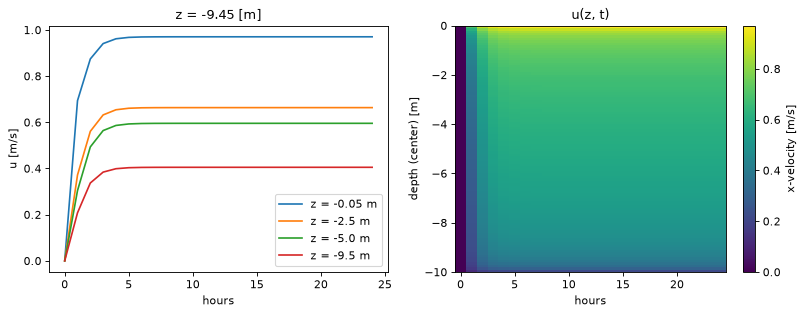

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for zsel in [-0.05, -2.5, -5.0, -9.5]:
    ds.u.sel(z=zsel, method='nearest').plot(ax=ax1, x='hours', label=f'z = {zsel} m')
ax1.set_ylabel('u [m/s]'); ax1.legend()
ds.u.plot(ax=ax2, x='hours', y='z', cmap='viridis')
ax2.set_title('u(z, t)');

## The final velocity profile

Compare the profile at the end of the run with the laminar Couette profile, which is a straight line between the no-slip bottom and the surface velocity.

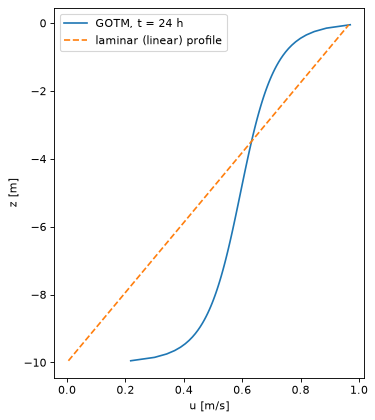

In [4]:
u = ds.u.isel(time=-1)
z = ds.z.values
H = float(-ds.zi.isel(zi=0))
u_surf = float(u.isel(z=-1))
u_lam = u_surf * (1 + z / H)

fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(u, z, label='GOTM, t = 24 h')
ax.plot(u_lam, z, '--', label='laminar (linear) profile')
ax.set_xlabel('u [m/s]'); ax.set_ylabel('z [m]'); ax.legend();

## The shape of the profile near the bottom

Plot the lower half of the profile against the height above the bottom on a logarithmic axis. The law of the wall is

$$u = \frac{u_*}{\kappa}\ln\frac{z' + z_0}{z_0}, \qquad z_0 = 0.03\, h_{0b},$$

with $z'$ the height above the bottom and $u_*$ the bottom friction velocity, which GOTM writes as `u_taub`. In wall units, $z^+ = z' u_* / \nu$ with $\nu = 1.3 \times 10^{-6}$ m$^2$/s.

bottom friction velocity u_* = 0.0316 m/s


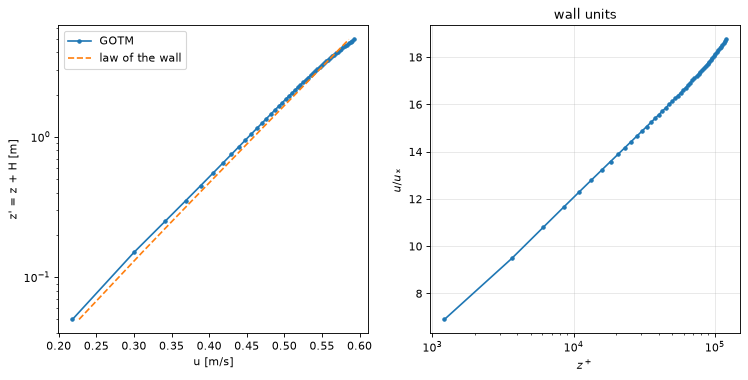

In [5]:
nu = 1.3e-6
kappa = 0.4
z0 = 0.03 * 0.1                           # bottom roughness length [m]
u_star_b = float(ds.u_taub.isel(time=-1))  # bottom friction velocity
z_above = z + H
u_log = analysis.law_of_the_wall(z_above, u_star_b, z0, kappa)
z_plus = z_above * u_star_b / nu
print(f'bottom friction velocity u_* = {u_star_b:.4f} m/s')

lower = z_above < H / 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
ax1.semilogy(u[lower], z_above[lower], 'o-', ms=3, label='GOTM')
ax1.semilogy(u_log[lower], z_above[lower], '--', label='law of the wall')
ax1.set_xlabel('u [m/s]'); ax1.set_ylabel("z' = z + H [m]"); ax1.legend()
ax2.semilogx(z_plus[lower], u[lower] / u_star_b, 'o-', ms=3)
ax2.set_xlabel('$z^+$'); ax2.set_ylabel('$u / u_*$'); ax2.grid(alpha=0.3)
ax2.set_title('wall units');

For the fit of the logarithmic layer and of the core region, `numpy.polyfit` on the appropriate variables is enough. Choose the range of $z^+$ yourself, from the plot above.

In [6]:
# example: a fit of u = a ln(z') + b over a range of z^+ that you choose
zp_min, zp_max = 2e3, 3e4                 # the first grid point is at z+ of about 1200
sel = (z_plus > zp_min) & (z_plus < zp_max)
a, b = np.polyfit(np.log(z_above[sel]), u.values[sel], 1)
print(f'fit over {zp_min} < z+ < {zp_max}:  u = {a:.4f} ln(z\') + {b:.4f}   ->   kappa = u_*/a = {u_star_b / a:.3f}')

fit over 2000.0 < z+ < 30000.0:  u = 0.0802 ln(z') + 0.4526   ->   kappa = u_*/a = 0.394


## The turbulent viscosity

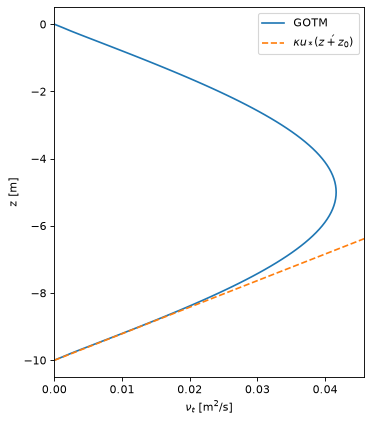

In [7]:
num = ds.num.isel(time=-1)
zi = ds.zi.values
fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(num, zi, label='GOTM')
ax.plot(analysis.eddy_viscosity_log_layer(zi + H, u_star_b, z0, kappa), zi, '--', label=r'$\kappa u_* (z\' + z_0)$')
ax.set_xlabel(r'$\nu_t$ [m$^2$/s]'); ax.set_ylabel('z [m]'); ax.set_xlim(0, float(num.max()) * 1.1)
ax.legend();

## Changing the setup

Any setting of the configuration can be changed through the dictionary passed to `run`. The keys are the nested names of `efmgotm/cases/couette.yaml`, joined by dots. For example, a smoother bottom and a weaker stress:

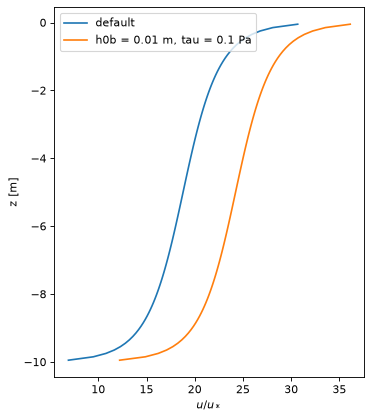

In [8]:
ds2 = efmgotm.run('couette', {'bottom.h0b': 0.01, 'surface.fluxes.tx.constant_value': 0.1}, name='smooth_weak', workdir=RUNS)
fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(ds.u.isel(time=-1) / float(ds.u_taub.isel(time=-1)), z, label='default')
ax.plot(ds2.u.isel(time=-1) / float(ds2.u_taub.isel(time=-1)), z, label='h0b = 0.01 m, tau = 0.1 Pa')
ax.set_xlabel('$u / u_*$'); ax.set_ylabel('z [m]'); ax.legend();

A constant horizontal pressure gradient can be added as well, which turns the Couette flow into a Couette-Poiseuille flow. In GOTM the external pressure gradient is given either as a surface slope or as a target depth-averaged velocity; see the `mimic_3d.ext_pressure` section of a full configuration (`gotm --write_yaml full.yaml --detail full` in a terminal), and the estuary exercise, where it is used.